# Modelo de conteo, validación espacial y brecha por zona

Este notebook corre `src/modelo.py` sobre `data/processed/modelo_250m.parquet` (ambas ciudades, solo celdas habitables) y responde la pregunta del proyecto: **qué zonas tienen hoy menos supermercados de los que su demanda y accesibilidad harían esperar.**

**Cómo se separan los datos**

| Paso | Datos | Para qué |
| --- | --- | --- |
| 0. Partición | Se aparta el **20% de los bloques de 3 km** como prueba final, sorteado por ciudad y según si el bloque tiene supermercado | Que exista un conjunto que no influya en ninguna decisión |
| 1–2. Desarrollo | El **80% restante**, con validación cruzada de 5 particiones por bloques de 3 km | Elegir la configuración del gradient boosting, comparar modelos, revisar la validación, la importancia y el GLM |
| 3. Prueba final | Se entrena con todo el desarrollo y se mide **una sola vez** en el 20% apartado | Reportar el desempeño esperado en zonas nuevas, con intervalos bootstrap y precisión/recall |
| 4. Sensibilidad | Las mismas reglas en cada tamaño de celda | Decidir el tamaño con datos de desarrollo |
| 5. Mapa final | Todas las celdas, 5 particiones por bloques, con la configuración ya elegida | Que cada celda tenga una predicción de un modelo que no vio su bloque, para calcular la brecha |

Los bloques son de 3 km porque el diagnóstico espacial (sección 5.6 del README) mostró que el parecido entre celdas se apaga entre 2 y 3 km. Un solo modelo usa ambas ciudades: cada ciudad pesa lo mismo y una variable indicadora permite que su nivel base sea distinto.

No necesita los datos crudos, salvo para poner el nombre de la comuna a cada zona (si `data/raw/` no está, la columna queda vacía). La corrida toma unos 4 minutos.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
from matplotlib.patches import Patch

from src import modelo

cfg = modelo.cargar_config("config.yaml")
salida = cfg["rutas"]["resultados_modelo"]
radio = cfg["decision"]["radio_brecha_m"]

COLORES = {"stgo": "#2a78d6", "ccp": "#eb6834"}
NOMBRES = {k: v["nombre"] for k, v in cfg["ciudades"].items()} | {"ambas": "Ambas ciudades"}
pd.set_option("display.precision", 3)
plt.rcParams.update({
    "font.size": 11, "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
})

def mapa_base(ax, d, valores, cmap, norm=None, vmin=None, vmax=None):
    """Dibuja una variable de las celdas de una ciudad como imagen (rápido y sin huecos)."""
    s = float(d["tamano_m"].iloc[0]) if "tamano_m" in d else float(cfg["modelo"]["tamano_m"])
    x0 = (d["x"] - (d["ix"] + 0.5) * s).iloc[0]
    y0 = (d["y"] - (d["iy"] + 0.5) * s).iloc[0]
    matriz = np.full((d["iy"].max() + 1, d["ix"].max() + 1), np.nan)
    matriz[d["iy"], d["ix"]] = valores
    im = ax.imshow(matriz, origin="lower", cmap=cmap, norm=norm, vmin=vmin, vmax=vmax, interpolation="nearest",
                   extent=[x0, x0 + matriz.shape[1] * s, y0, y0 + matriz.shape[0] * s])
    ax.set_xlim(d["x"].quantile(0.02) - 2000, d["x"].quantile(0.98) + 2000)
    ax.set_ylim(d["y"].quantile(0.02) - 2000, d["y"].quantile(0.98) + 2000)
    ax.set_axis_off()
    return im

## 1. Corrida completa

In [2]:
r = modelo.ejecutar(cfg)
mejor = r["mejor"]

[16:18:14] Tabla de 250 m: 24,948 celdas habitables, 34 variables, 679 supermercados


[16:18:14] Prueba final: 68 bloques, 5,224 celdas, 129 supermercados (no se usan hasta el paso 3)


[16:18:45] Gradient boosting elegido en desarrollo: {'learning_rate': 0.05, 'max_iter': 150, 'max_leaf_nodes': 7, 'min_samples_leaf': 100, 'l2_regularization': 1.0}


[16:18:52] Mejor modelo en desarrollo: Gradient boosting (Poisson) (D² = 0.343)


[16:19:36] Desarrollo listo (validaciones, importancia, coeficientes)


[16:19:44] Prueba final (Gradient boosting (Poisson)): D² = 0.405, PR-AUC = 0.300


... (3 outputs left out)

[16:20:50] Sensibilidad 1000 m: D² en desarrollo = 0.443


[16:21:05] Sensibilidad 250 m desplazada: D² en desarrollo = 0.344


[16:21:24] 30 zonas candidatas -> resultados/modelo/zonas_candidatas.csv


[16:21:24] Listo.


## 2. Partición: desarrollo (80%) y prueba final (20%)

El sorteo es por bloques de 3 km, no por celdas: así ninguna celda de prueba tiene a su vecina inmediata en el entrenamiento. Como los bloques tienen distinto número de celdas, la prueba queda cerca del 20% y no exactamente en 20%.

,conjunto,ciudad,bloques,celdas,pct_celdas,supermercados
0,desarrollo (80%),ccp,84,4380,75.3,127
1,desarrollo (80%),stgo,184,15344,80.2,423
2,desarrollo (80%),ambas,268,19724,79.1,550
3,prueba final (20%),ccp,22,1440,24.7,32
4,prueba final (20%),stgo,46,3784,19.8,97
5,prueba final (20%),ambas,68,5224,20.9,129


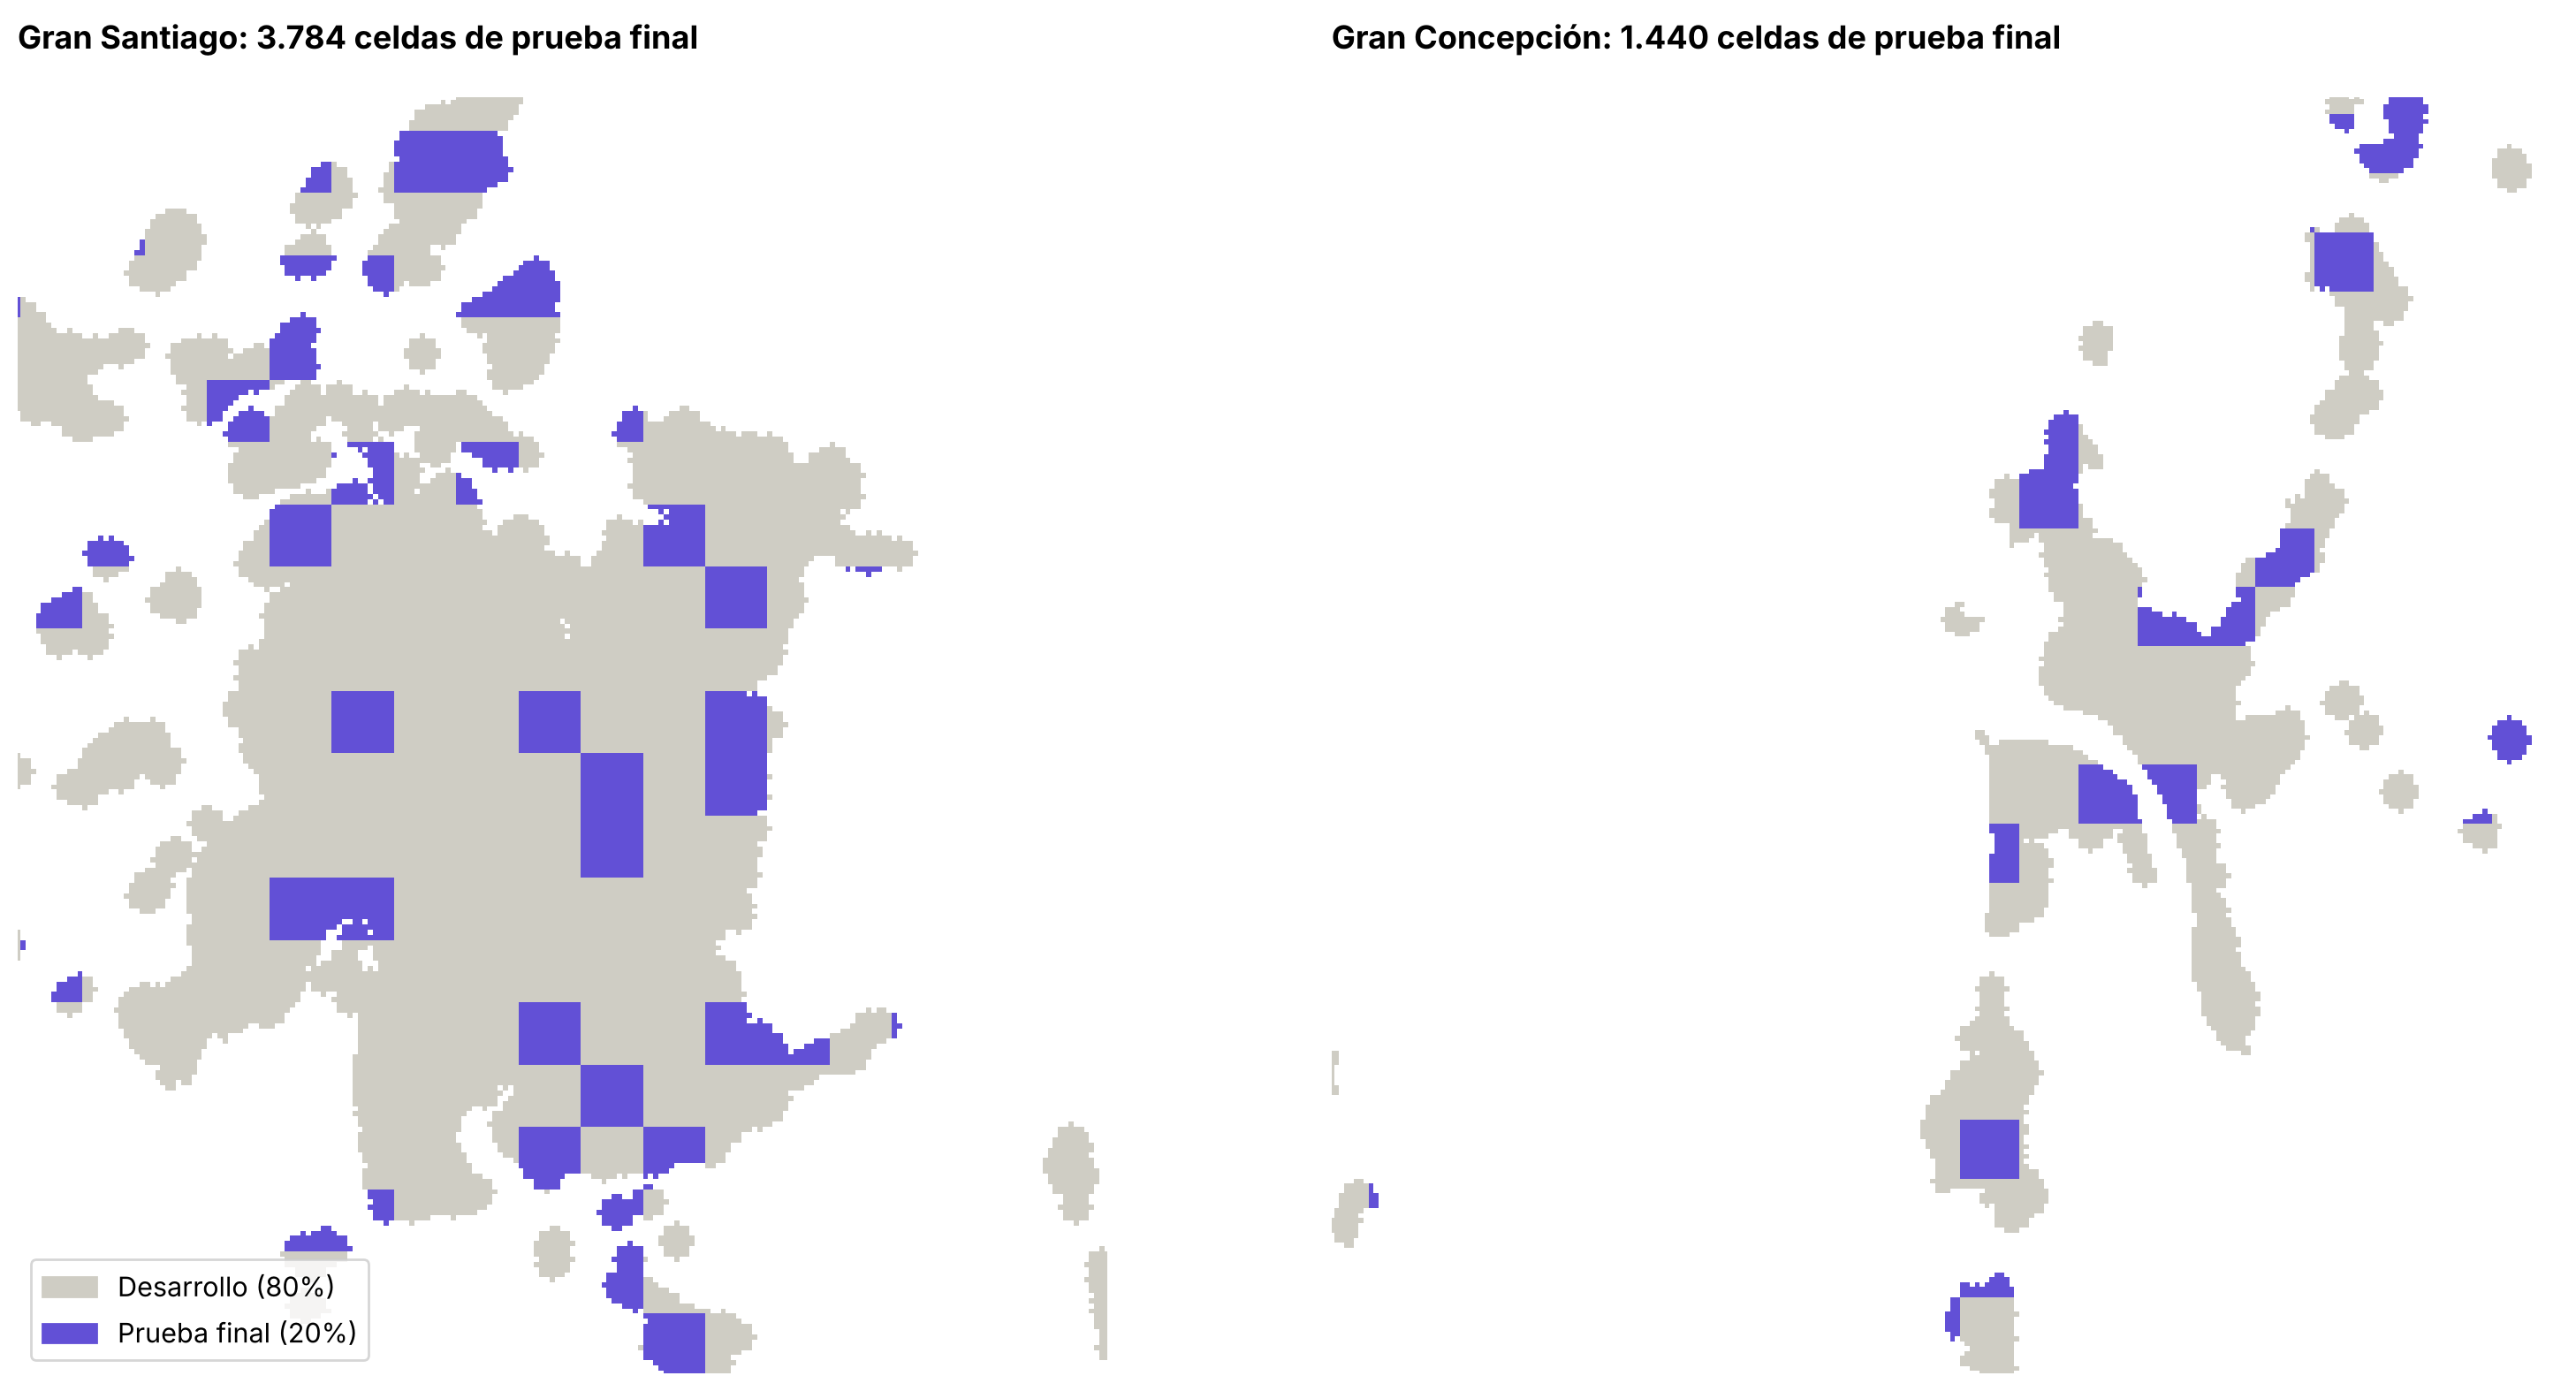

In [3]:
display(r["particion"].round(1))

fig, ejes = plt.subplots(1, 2, figsize=(16, 8))
dos_tonos = LinearSegmentedColormap.from_list("particion", ["#cfcdc4", "#6250d6"], N=2)
t = r["tabla"].assign(prueba=r["es_prueba"].astype(float))
for ciudad, ax in zip(["stgo", "ccp"], ejes):
    d = t[t["ciudad"] == ciudad]
    mapa_base(ax, d, d["prueba"], dos_tonos, vmin=0, vmax=1)
    ax.set_title(f"{NOMBRES[ciudad]}: {int(d['prueba'].sum()):,} celdas de prueba final".replace(",", "."))
ejes[0].legend(handles=[Patch(color="#cfcdc4", label="Desarrollo (80%)"), Patch(color="#6250d6", label="Prueba final (20%)")],
               loc="lower left", frameon=True)
fig.tight_layout()
fig.savefig(f"{salida}/particion_prueba_final.png", dpi=200, bbox_inches="tight", facecolor="white")
plt.show()

## 3. Desarrollo: ajuste ligero del gradient boosting

Las configuraciones de `config.yaml` se comparan con validación cruzada **dentro del 80% de desarrollo**. La prueba final no participa en esta elección. Las configuraciones complejas aprenden los polos comerciales de entrenamiento y subestiman el total fuera de muestra (`esperados_sobre_observados` < 1).

In [4]:
r["ajuste_gbm"]

,learning_rate,max_iter,max_leaf_nodes,min_samples_leaf,l2_regularization,d2_ambas,d2_ccp,d2_stgo,pr_auc_ambas,esperados_sobre_observados
0,0.05,150,7,100,1.0,0.343,0.414,0.322,0.232,1.005
1,0.03,300,7,100,1.0,0.340,0.412,0.319,0.231,0.990
2,0.05,200,5,150,1.0,0.338,0.409,0.316,0.224,1.016
3,0.05,300,15,40,1.0,0.301,0.363,0.283,0.217,0.746


## 4. Desarrollo: comparación de modelos

- **D² de Poisson:** fracción de la devianza explicada respecto de predecir el promedio (0 = nada, 1 = perfecto).
- **PR-AUC:** qué tan bien ordena las celdas con supermercado sobre las sin supermercado (el azar da ~0,02).
- **Captura top 5%:** qué porcentaje de los supermercados cae en el 5% de celdas con mayor predicción.

El modelo final se elige aquí, con el mayor D² en desarrollo.

In [5]:
comp = r["comparacion"]
des = comp[comp["conjunto"] == "validación cruzada (80%)"]
des.pivot_table(index="modelo", columns="ciudad", values=["d2_poisson", "pr_auc", "captura_top5", "esperados", "observados"],
                sort=False)[["d2_poisson", "pr_auc", "captura_top5", "esperados", "observados"]].round(3)

d2_poisson               pr_auc                \
ciudad                             ccp   stgo  ambas    ccp   stgo  ambas   
modelo                                                                      
Nulo (promedio por ciudad)      -0.004 -0.004 -0.004  0.024  0.022  0.023   
Poisson (GLM)                    0.182  0.270  0.250  0.245  0.191  0.203   
Gradient boosting (Poisson)      0.414  0.322  0.343  0.285  0.213  0.232   

                            captura_top5                 esperados           \
ciudad                               ccp    stgo   ambas       ccp     stgo   
modelo                                                                        
Nulo (promedio por ciudad)         3.937   4.492   4.000   128.777  423.165   
Poisson (GLM)                     51.181  41.135  44.909   226.690  447.817   
Gradient boosting (Poisson)       53.543  48.936  50.182   123.876  428.680   

                                     observados                
ciudad                         ambas        ccp   stgo  ambas  
modelo                                                         
Nulo (promedio por ciudad)   551.942      127.0  423.0  550.0  
Poisson (GLM)                674.507      127.0  423.0  550.0  
Gradient boosting (Poisson)  552.556      127.0  423.0  550.0

## 5. Desarrollo: ¿validación aleatoria o por bloques?

Si las celdas de prueba son vecinas de las de entrenamiento, el modelo se evalúa con información que en la práctica no tendría y las métricas salen infladas.

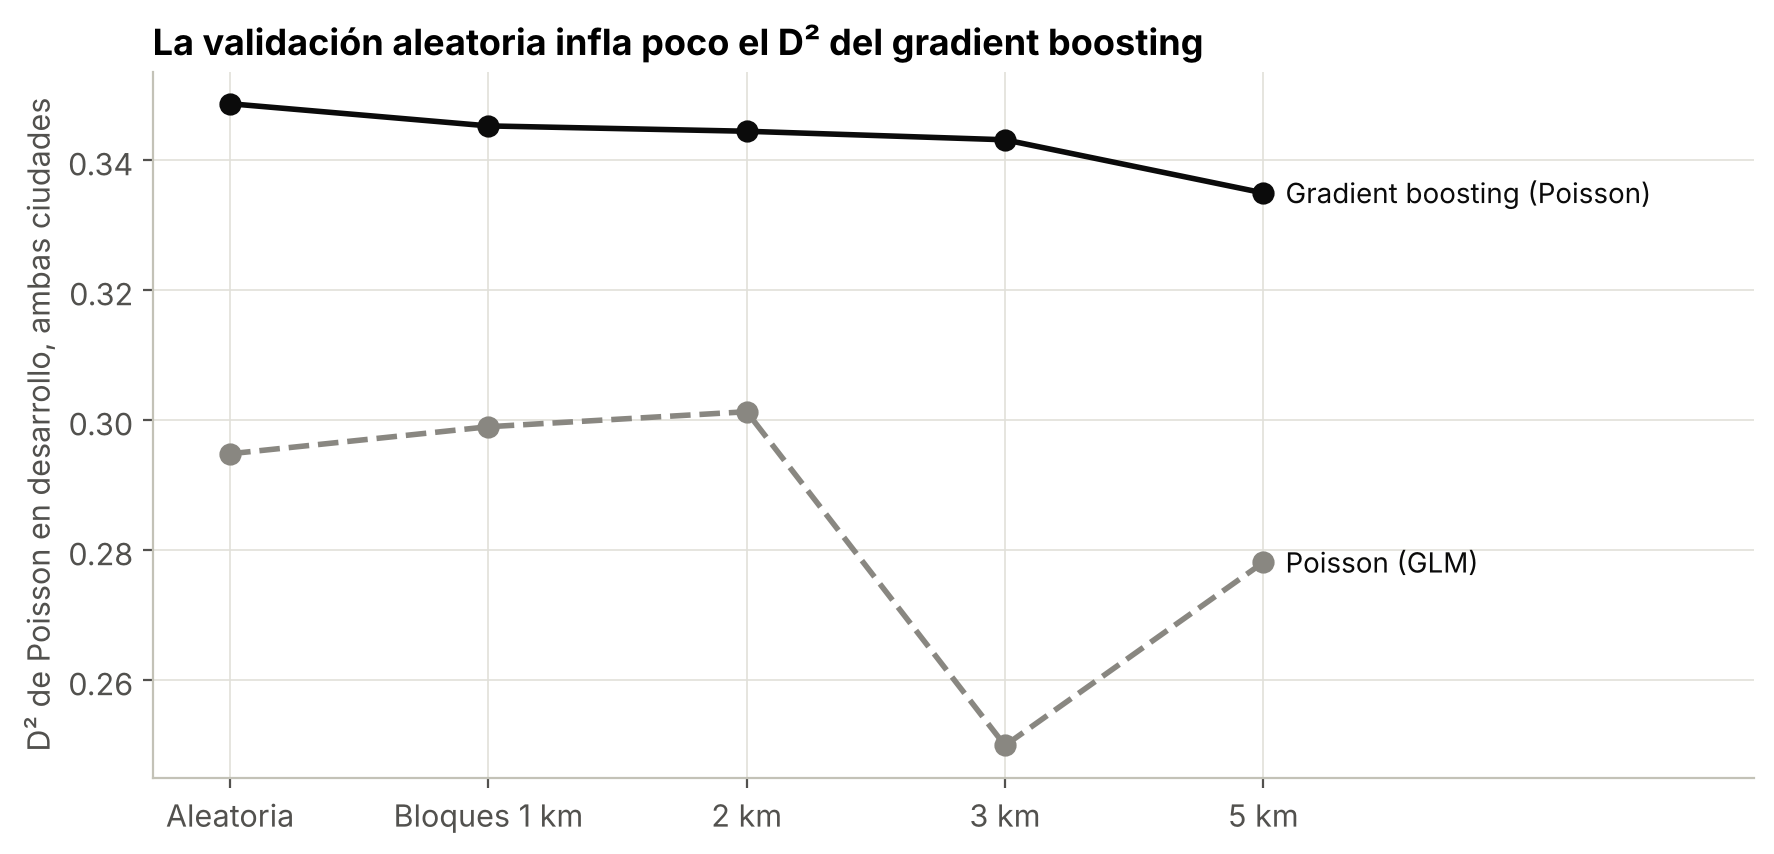

ciudad                                         ccp   stgo  ambas
validacion      modelo                                          
aleatoria       Poisson (GLM)                0.331  0.284  0.295
                Gradient boosting (Poisson)  0.394  0.335  0.349
bloques de 1 km Poisson (GLM)                0.334  0.288  0.299
                Gradient boosting (Poisson)  0.388  0.332  0.345
bloques de 2 km Poisson (GLM)                0.335  0.291  0.301
                Gradient boosting (Poisson)  0.406  0.326  0.344
bloques de 3 km Poisson (GLM)                0.182  0.270  0.250
                Gradient boosting (Poisson)  0.414  0.322  0.343
bloques de 5 km Poisson (GLM)                0.252  0.286  0.278
                Gradient boosting (Poisson)  0.356  0.329  0.335

In [6]:
val = r["validaciones"]
v = val[val["ciudad"] == "ambas"]
esquemas = ["aleatoria"] + [f"bloques de {int(l / 1000)} km" for l in cfg["modelo"]["bloques_sensibilidad_m"]]
fig, ax = plt.subplots(figsize=(9, 4.4))
for nombre_modelo, estilo in [("Gradient boosting (Poisson)", dict(color="#0b0b0b", linestyle="-")),
                              ("Poisson (GLM)", dict(color="#898781", linestyle="--"))]:
    d = v[v["modelo"] == nombre_modelo].set_index("validacion").loc[esquemas, "d2_poisson"]
    ax.plot(range(len(esquemas)), d, marker="o", markersize=7, linewidth=2, **estilo)
    ax.annotate(nombre_modelo, (len(esquemas) - 1, d.iloc[-1]), xytext=(8, 0), textcoords="offset points",
                va="center", fontsize=10, color="#0b0b0b")
ax.set_xticks(range(len(esquemas)), ["Aleatoria", "Bloques 1 km", "2 km", "3 km", "5 km"])
ax.set_ylabel("D² de Poisson en desarrollo, ambas ciudades")
ax.set_xlim(-0.3, len(esquemas) + 0.9)
ax.set_title("La validación aleatoria infla poco el D² del gradient boosting")
fig.tight_layout()
fig.savefig(f"{salida}/validacion_bloques.png", dpi=200, bbox_inches="tight", facecolor="white")
plt.show()
val.pivot_table(index=["validacion", "modelo"], columns="ciudad", values="d2_poisson", sort=False).round(3)

## 6. Prueba final (20%)

Los tres modelos se entrenan con todo el desarrollo y se miden una sola vez en los bloques apartados. Los intervalos del 95% vienen de remuestrear los bloques de prueba 1.000 veces (dentro de cada ciudad): con 68 bloques, la estimación tiene bastante variación, sobre todo en Concepción (22 bloques).

d2_poisson               pr_auc                \
ciudad                             ccp   stgo  ambas    ccp   stgo  ambas   
modelo                                                                      
Nulo (promedio por ciudad)      -0.009 -0.001 -0.003  0.017  0.025  0.022   
Poisson (GLM)                    0.449  0.327  0.360  0.447  0.267  0.307   
Gradient boosting (Poisson)      0.542  0.354  0.405  0.476  0.261  0.300   

                            roc_auc               captura_top5                  
ciudad                          ccp   stgo  ambas          ccp    stgo   ambas  
modelo                                                                          
Nulo (promedio por ciudad)    0.500  0.500  0.466        0.000   0.000   4.651  
Poisson (GLM)                 0.946  0.891  0.904       65.625  48.454  51.163  
Gradient boosting (Poisson)   0.957  0.903  0.917       81.250  48.454  56.589

ic95_inf                 ic95_sup                 
ciudad          ambas     ccp    stgo    ambas      ccp    stgo
metrica                                                        
captura_top5   45.160  55.546  37.680   70.646  100.000  64.588
d2_poisson      0.321   0.396   0.263    0.481    0.669   0.437
pr_auc          0.216   0.300   0.173    0.385    0.665   0.348

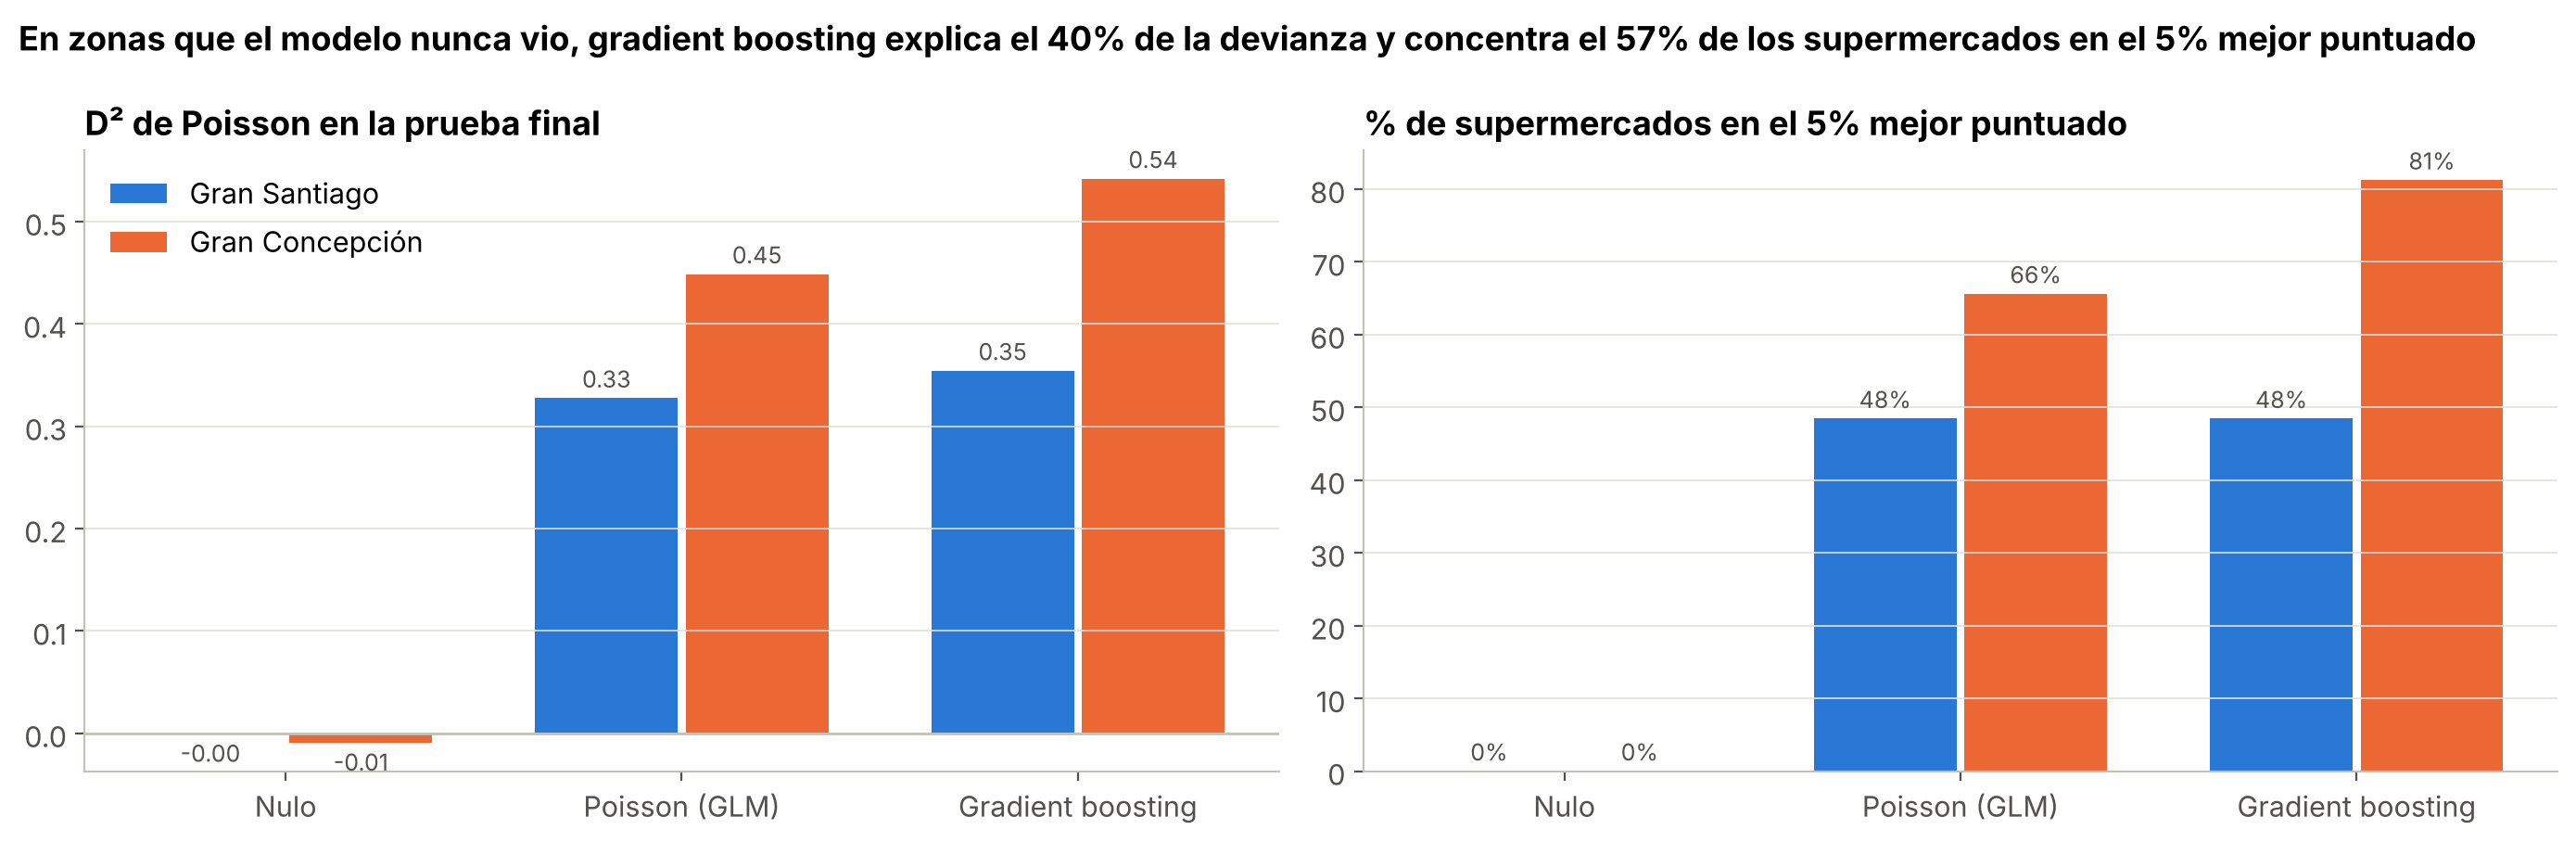

In [7]:
fin = comp[comp["conjunto"] == "prueba final (20%)"]
display(fin.pivot_table(index="modelo", columns="ciudad", values=["d2_poisson", "pr_auc", "roc_auc", "captura_top5"],
                        sort=False)[["d2_poisson", "pr_auc", "roc_auc", "captura_top5"]].round(3))
display(r["intervalos"].pivot_table(index="metrica", columns="ciudad", values=["ic95_inf", "ic95_sup"]).round(3))

fig, ejes = plt.subplots(1, 2, figsize=(14, 4.6))
orden = list(modelo.NOMBRES_MODELOS.values())
for ax, metrica, titulo in [(ejes[0], "d2_poisson", "D² de Poisson en la prueba final"),
                            (ejes[1], "captura_top5", "% de supermercados en el 5% mejor puntuado")]:
    for i, ciudad in enumerate(["stgo", "ccp"]):
        d = fin[fin["ciudad"] == ciudad].set_index("modelo").loc[orden, metrica]
        barras = ax.bar(np.arange(3) + (i - 0.5) * 0.38, d, width=0.36, color=COLORES[ciudad], label=NOMBRES[ciudad])
        ax.bar_label(barras, fmt="%.2f" if metrica == "d2_poisson" else "%.0f%%", fontsize=9, color="#52514e", padding=2)
    ax.set_xticks(np.arange(3), ["Nulo", "Poisson (GLM)", "Gradient boosting"])
    ax.set_title(titulo)
    ax.grid(axis="x", visible=False)
    ax.axhline(0, color="#c3c2b7", linewidth=1)
ejes[0].legend(frameon=False, loc="upper left")
g = fin[(fin["clave"] == mejor) & (fin["ciudad"] == "ambas")].iloc[0]
fig.suptitle(f"En zonas que el modelo nunca vio, gradient boosting explica el {100 * g['d2_poisson']:.0f}% de la devianza "
             f"y concentra el {g['captura_top5']:.0f}% de los supermercados en el 5% mejor puntuado",
             x=0.01, ha="left", fontsize=13, fontweight="bold")
fig.tight_layout()
fig.savefig(f"{salida}/comparacion_modelos.png", dpi=200, bbox_inches="tight", facecolor="white")
plt.show()

## 7. Precisión y recall según el largo de la lista (prueba final)

Si se marca como "con supermercado" el k% de celdas con mayor predicción:

- **Precisión:** de las celdas marcadas, qué porcentaje tiene supermercado.
- **Recall:** de las celdas con supermercado, qué porcentaje quedó marcado.

**Por qué no se optimiza la precisión.** En la presentación de avance se propuso priorizar la precisión, cuando el modelo era un clasificador de presencia. Con la pregunta nueva, las celdas que el modelo puntúa alto y no tienen supermercado (los "falsos positivos") son justamente las oportunidades de las que sale la brecha: un modelo con precisión perfecta solo marcaría lugares que ya tienen supermercado. Por eso el modelo se entrena con la devianza de Poisson y la precisión se reporta para validar que el puntaje reconoce lugares "tipo supermercado".

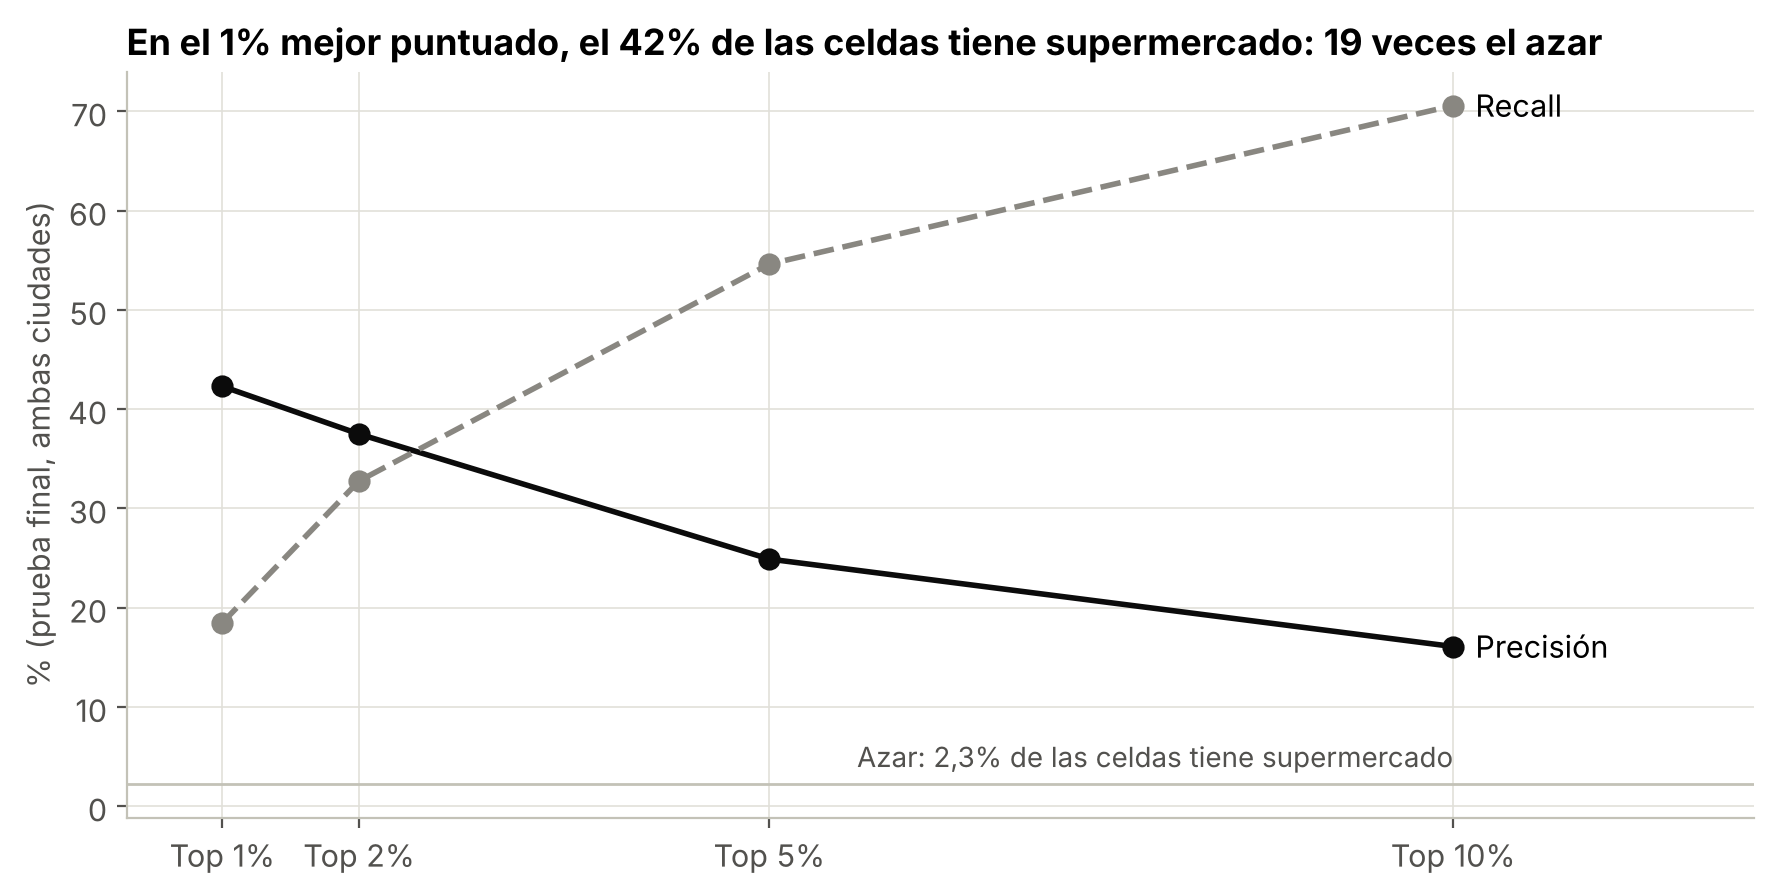

celdas_marcadas               precision             recall_celdas  \
ciudad            ambas    ccp   stgo     ambas   ccp  stgo         ambas   
top_pct                                                                     
1                  52.0   14.0   38.0      42.3  57.1  36.8          18.5   
2                 104.0   29.0   76.0      37.5  48.3  34.2          32.8   
5                 261.0   72.0  189.0      24.9  26.4  24.3          54.6   
10                522.0  144.0  378.0      16.1  14.6  16.7          70.6   

                     
ciudad    ccp  stgo  
top_pct              
1        32.0  14.9  
2        56.0  27.7  
5        76.0  48.9  
10       84.0  67.0

In [8]:
pr = r["precision_recall"]
d = pr[pr["ciudad"] == "ambas"]
fig, ax = plt.subplots(figsize=(9, 4.6))
ax.plot(d["top_pct"], d["precision"], color="#0b0b0b", linewidth=2, marker="o", markersize=7)
ax.plot(d["top_pct"], d["recall_celdas"], color="#898781", linewidth=2, linestyle="--", marker="o", markersize=7)
ax.axhline(d["tasa_base"].iloc[0], color="#c3c2b7", linewidth=1)
ax.annotate("Precisión", (d["top_pct"].iloc[-1], d["precision"].iloc[-1]), xytext=(8, 0), textcoords="offset points", va="center")
ax.annotate("Recall", (d["top_pct"].iloc[-1], d["recall_celdas"].iloc[-1]), xytext=(8, 0), textcoords="offset points", va="center")
ax.annotate(f"Azar: {d['tasa_base'].iloc[0]:.1f}% de las celdas tiene supermercado".replace(".", ","),
            (d["top_pct"].iloc[-1], d["tasa_base"].iloc[0]), xytext=(0, 6), textcoords="offset points", ha="right",
            fontsize=10, color="#52514e")
ax.set_xticks(d["top_pct"], [f"Top {k}%" for k in d["top_pct"]])
ax.set_xlim(0.3, d["top_pct"].iloc[-1] + 2.2)
ax.set_ylabel("% (prueba final, ambas ciudades)")
p1 = d.iloc[0]
ax.set_title(f"En el 1% mejor puntuado, el {p1['precision']:.0f}% de las celdas tiene supermercado: "
             f"{p1['precision'] / p1['tasa_base']:.0f} veces el azar")
fig.tight_layout()
fig.savefig(f"{salida}/precision_recall_top.png", dpi=200, bbox_inches="tight", facecolor="white")
plt.show()
pr.pivot_table(index="top_pct", columns="ciudad", values=["precision", "recall_celdas", "celdas_marcadas"]).round(1)

## 8. Qué variables pesan (desarrollo)

**Importancia por permutación** del mejor modelo, medida en los bloques de prueba de la validación cruzada de desarrollo: cuánto cae el D² si se desordena una variable. Con variables correlacionadas (por ejemplo, población a 500 m y a 1 km) la importancia se reparte entre ellas.

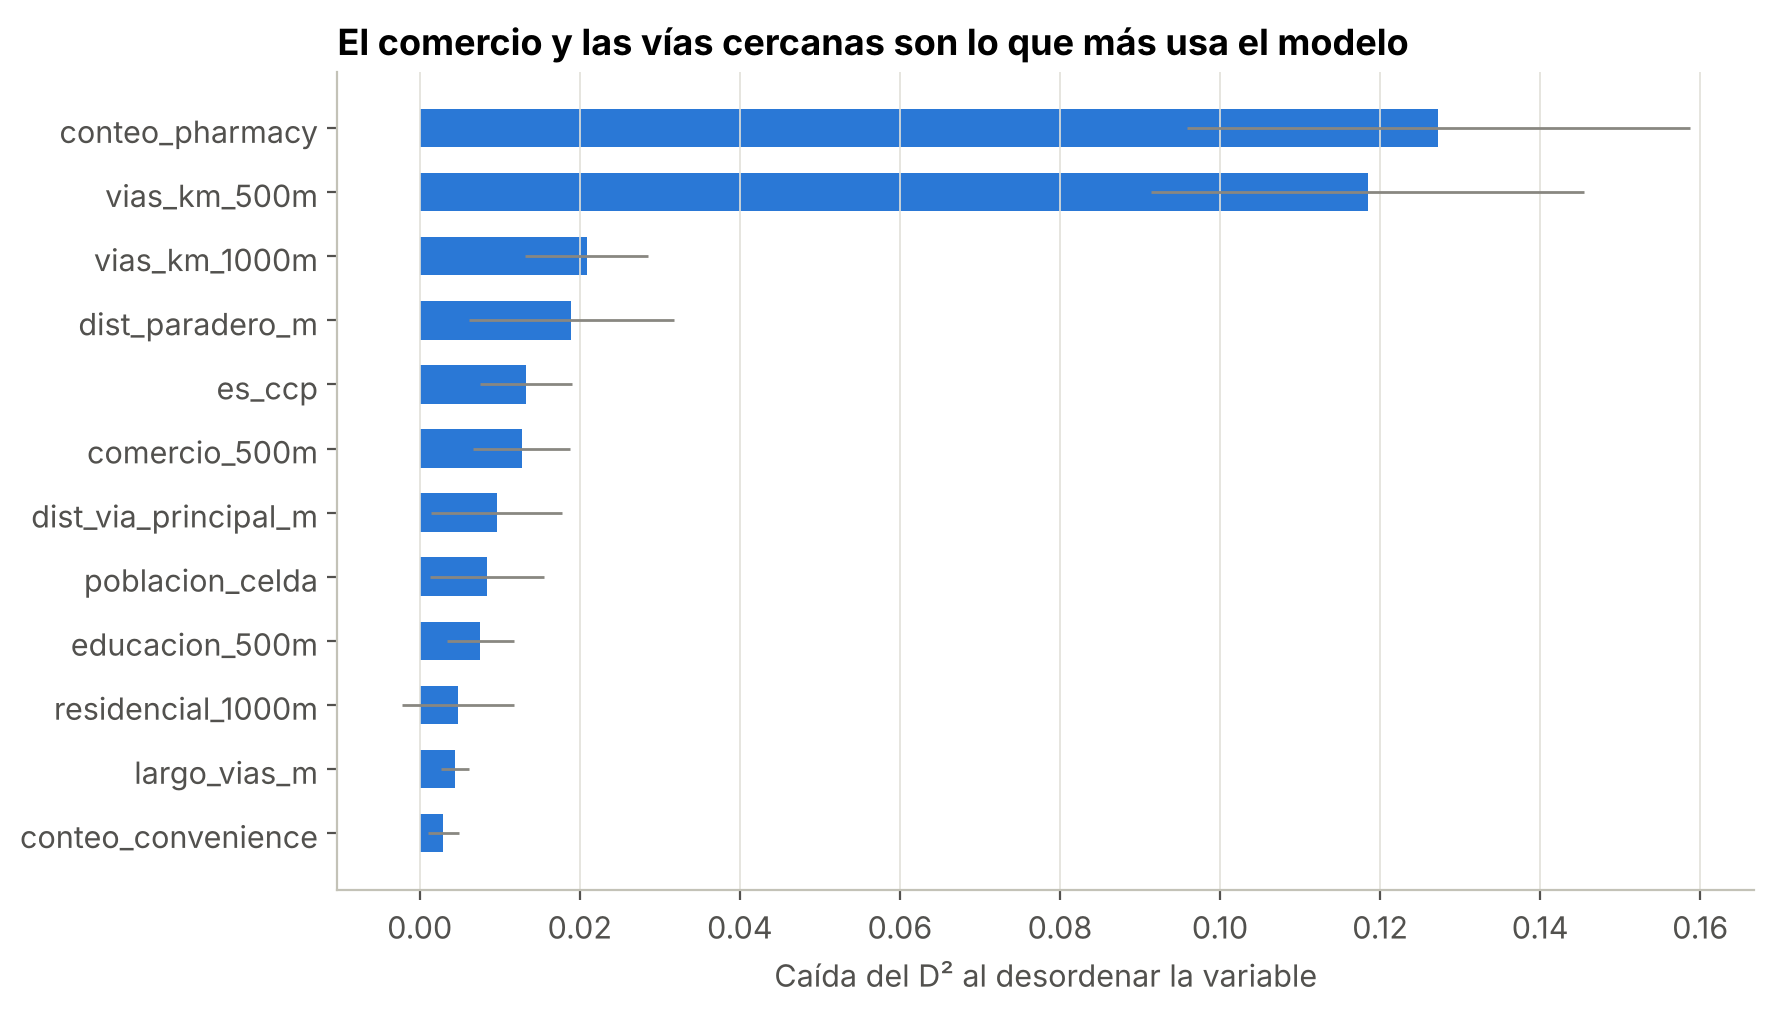

In [9]:
imp = r["importancia"].head(12).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 5.2))
ax.barh(imp["variable"], imp["caida_d2"], xerr=imp["desv"], color="#2a78d6", height=0.6,
        error_kw=dict(ecolor="#898781", lw=1))
ax.set_xlabel("Caída del D² al desordenar la variable")
ax.set_title("El comercio y las vías cercanas son lo que más usa el modelo")
ax.grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig(f"{salida}/importancia_variables.png", dpi=200, bbox_inches="tight", facecolor="white")
plt.show()

**Coeficientes del GLM de Poisson** ajustado con el desarrollo (variables en log(1 + x) y estandarizadas): la razón de tasas indica por cuánto se multiplica el número esperado de supermercados cuando la variable sube una desviación estándar, con las demás fijas. Pares muy correlacionados, como vías a 500 m y a 1 km, pueden salir con signos opuestos y se leen juntos. Debajo, la prueba de sobredispersión contra una Binomial Negativa.

In [10]:
display(r["coeficientes"].head(12).round(3))
pd.Series(r["dispersion"]).round(4)

,variable,coef,razon_tasas,ic95_inf,ic95_sup,p_valor
0,vias_km_500m,1.088,2.969,1.940,4.544,0.000
1,vias_km_1000m,-0.883,0.413,0.244,0.699,0.001
2,es_ccp,0.669,1.952,1.524,2.500,0.000
3,pob_500m,0.649,1.913,1.081,3.385,0.026
4,pob_1000m,0.494,1.638,0.997,2.693,0.051
5,comercio_500m,0.329,1.390,1.168,1.653,0.000
6,largo_vias_m,0.306,1.358,1.123,1.643,0.002
7,poblacion_celda,-0.293,0.746,0.546,1.020,0.067
8,dist_paradero_m,-0.258,0.773,0.639,0.935,0.008
9,residencial_500m,0.241,1.273,0.800,2.025,0.309


alpha_binomial_negativa      6.374e-01
p_valor_alpha                6.000e-04
aic_poisson                  3.826e+03
aic_binomial_negativa        3.809e+03
devianza_sobre_gl_poisson    1.382e-01
dtype: float64

## 9. Sensibilidad al tamaño de celda (desarrollo)

El mismo modelo en todas las grillas, con los mismos bloques de prueba final apartados. Las métricas son de validación cruzada en desarrollo. Para comparar zonas, la brecha de cada grilla se suma en cuadrados de 1 km comunes a todas.

In [11]:
r["sensibilidad"].pivot_table(index="celda", columns="ciudad", sort=False,
                             values=["d2_poisson", "captura_top5", "coincidencia_top50_km2", "spearman_brecha_km2"]).round(3)

d2_poisson               captura_top5                  \
ciudad                  ccp   stgo  ambas          ccp    stgo   ambas   
celda                                                                    
125 m                 0.316  0.276  0.285       45.669  49.173  51.091   
250 m                 0.414  0.322  0.343       53.543  48.936  50.182   
500 m                 0.548  0.393  0.431       51.181  32.624  37.818   
1000 m                0.559  0.401  0.443       33.071  13.981  18.215   
250 m desplazada      0.349  0.342  0.344       45.312  50.824  49.548   

                 coincidencia_top50_km2        spearman_brecha_km2         
ciudad                              ccp   stgo                 ccp   stgo  
celda                                                                      
125 m                              78.0   76.0               0.903  0.957  
250 m                             100.0  100.0               1.000  1.000  
500 m                              78.0   66.0               0.905  0.941  
1000 m                             78.0   62.0               0.840  0.885  
250 m desplazada                   64.0   52.0               0.677  0.729

## 10. Correlación espacial de los residuos (mapa final)

I de Moran con las 8 celdas vecinas (360 m), de la variable objetivo y de los residuos de Pearson de las predicciones del mapa final. Si el modelo captura la estructura espacial, el I de los residuos debe quedar cerca de 0.

In [12]:
r["moran"].pivot_table(index="variable", columns="ciudad", values=["I", "p_sim"]).round(4)

I         p_sim       
ciudad                ccp   stgo    ccp   stgo
variable                                      
n_supermercados     0.101  0.064  0.001  0.001
residuo de Pearson  0.017  0.011  0.022  0.013

## 11. Brecha y zonas candidatas (mapa final)

La brecha de cada celda es la suma de supermercados **esperados** en 1 km a la redonda menos los **observados** en ese radio. Las predicciones salen de 5 particiones por bloques sobre todas las celdas, con la configuración elegida en desarrollo, y se **calibran por ciudad** para que el total esperado sea igual al observado: así no aparecen "faltantes" solo porque el modelo subestima el total de una ciudad. El factor no cambia el orden de las celdas dentro de cada ciudad.

Reglas de decisión (`config.yaml`, sección `decision`):

- sin supermercados a 500 m o menos;
- población en 1 km sobre la mediana de las celdas habitables de su ciudad;
- brecha positiva;
- se elige la celda de mayor brecha, se descartan las que están a menos de 1,5 km de ella y se repite, hasta 15 zonas por ciudad.

In [13]:
r["calibracion"].round(3)

,ciudad,observados,esperados_sin_calibrar,factor
0,ccp,159,141.115,1.127
1,stgo,520,532.092,0.977


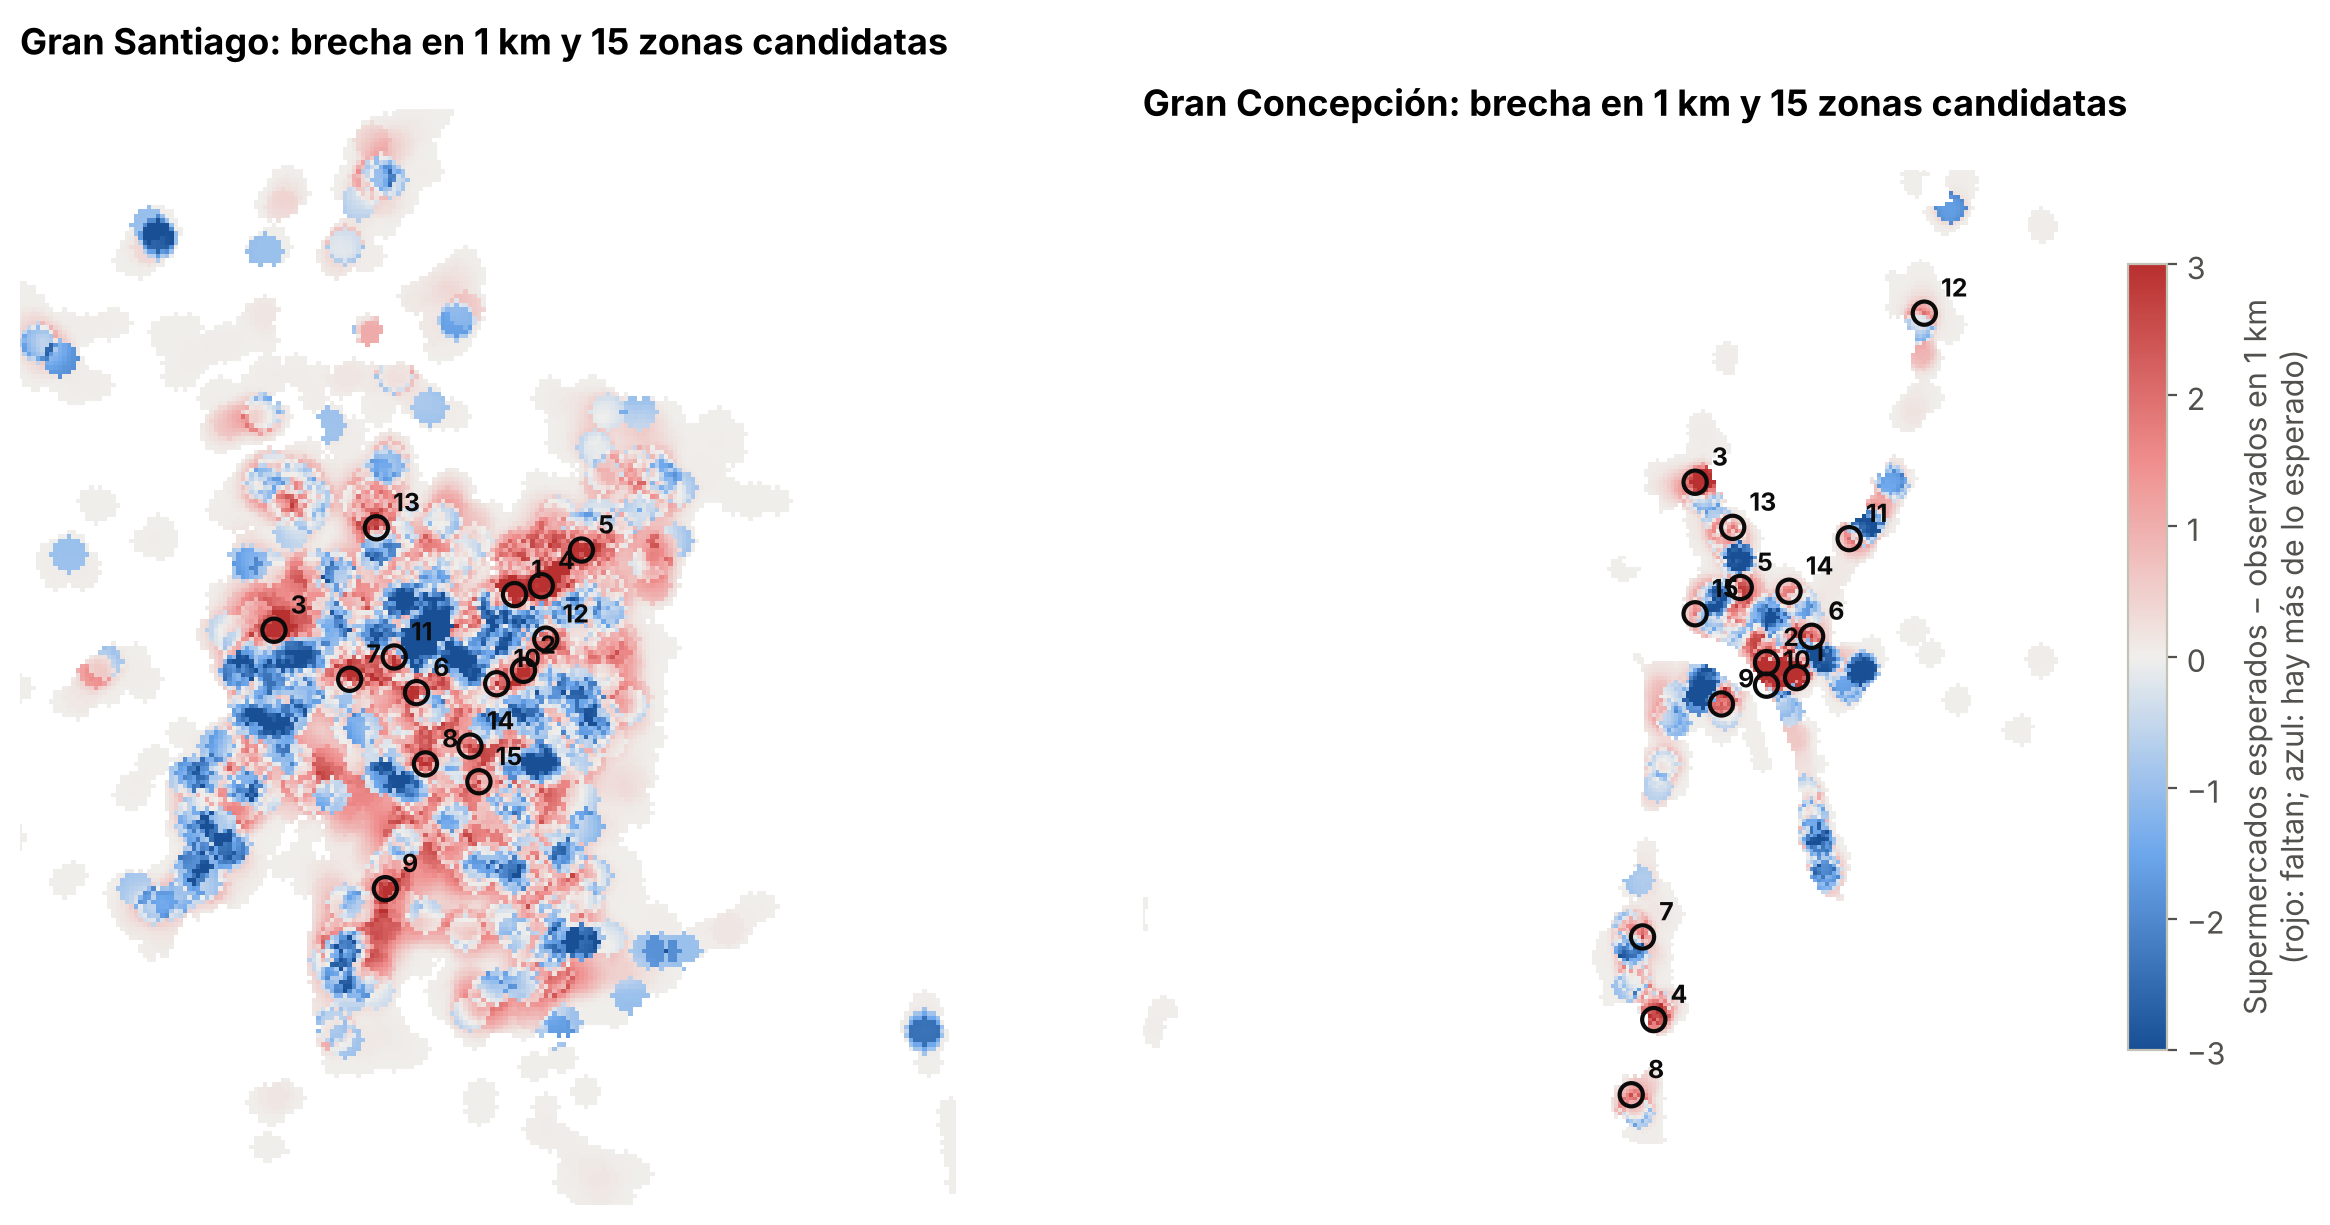

In [14]:
pred = r["predicciones"]
cand = r["candidatas"]
divergente = LinearSegmentedColormap.from_list("brecha", ["#184f95", "#6da7ec", "#f0efec", "#ef8e8d", "#b8302f"])
fig, ejes = plt.subplots(1, 2, figsize=(16, 8.5))
for ciudad, ax in zip(["stgo", "ccp"], ejes):
    d = pred[pred["ciudad"] == ciudad]
    im = mapa_base(ax, d, d[f"brecha_{radio}m"], divergente, norm=TwoSlopeNorm(0, -3, 3))
    k = cand[cand["ciudad"] == ciudad].merge(d[["id_celda", "x", "y"]], on="id_celda")
    ax.scatter(k["x"], k["y"], s=70, facecolors="none", edgecolors="#0b0b0b", linewidths=1.5)
    for _, f in k.iterrows():
        ax.annotate(str(f["ranking"]), (f["x"], f["y"]), xytext=(6, 6), textcoords="offset points",
                    fontsize=9, fontweight="bold", color="#0b0b0b")
    ax.set_title(f"{NOMBRES[ciudad]}: brecha en {radio / 1000:.0f} km y {len(k)} zonas candidatas")
barra = fig.colorbar(im, ax=ejes, shrink=0.6, pad=0.02)
barra.set_label("Supermercados esperados − observados en 1 km\n(rojo: faltan; azul: hay más de lo esperado)")
fig.savefig(f"{salida}/mapa_brecha_250m.png", dpi=200, bbox_inches="tight", facecolor="white")
plt.show()

In [15]:
cand[["ciudad", "ranking", "comuna", f"brecha_{radio}m", f"esperado_{radio}m", f"n_super_{radio}m",
      "dist_super_m", "pob_1000m", "paraderos_500m", "comercio_500m", "puntaje_idoneidad", "mapa"]].round(2)

,ciudad,ranking,comuna,brecha_1000m,esperado_1000m,n_super_1000m,dist_super_m,pob_1000m,paraderos_500m,comercio_500m,puntaje_idoneidad,mapa
21707,ccp,1,CONCEPCIÓN,7.77,12.77,5,559.0,17104,10,4,93.8,"https://www.google.com/maps?q=-36.830648,-73.0..."
21928,ccp,2,CONCEPCIÓN,5.50,9.50,4,750.0,21346,10,1,96.4,"https://www.google.com/maps?q=-36.822005,-73.0..."
23785,ccp,3,TALCAHUANO,4.34,5.34,1,559.0,12862,16,2,85.3,"https://www.google.com/maps?q=-36.714741,-73.1..."
19452,ccp,4,CORONEL,3.39,4.39,1,750.0,5742,6,1,87.5,"https://www.google.com/maps?q=-37.037327,-73.1..."
22864,ccp,5,TALCAHUANO,2.83,2.83,0,1030.8,18269,10,0,93.7,"https://www.google.com/maps?q=-36.777274,-73.0..."
22311,ccp,6,CONCEPCIÓN,2.80,2.80,0,1030.8,25583,14,0,82.1,"https://www.google.com/maps?q=-36.805687,-73.0..."
19916,ccp,7,CORONEL,2.72,3.72,1,559.0,25100,10,8,69.5,"https://www.google.com/maps?q=-36.987905,-73.1..."
19314,ccp,8,LOTA,2.51,2.51,0,1030.8,18345,10,0,86.4,"https://www.google.com/maps?q=-37.082638,-73.1..."
21310,ccp,9,SAN PEDRO DE LA PAZ,2.36,5.36,3,559.0,9569,12,5,89.8,"https://www.google.com/maps?q=-36.847325,-73.0..."
21593,ccp,10,CONCEPCIÓN,2.33,6.33,4,750.0,9859,6,3,81.5,"https://www.google.com/maps?q=-36.835519,-73.0..."


## 12. Cómo leer los resultados

- **El modelo no dice dónde *debe* haber un supermercado**, sino dónde la configuración actual de demanda, accesibilidad y comercio se parece a la de lugares que sí tienen. La brecha es una señal para priorizar visitas, no una recomendación de inversión.
- **El modelo aprende de las decisiones pasadas de las cadenas**, con sus sesgos (por ejemplo, socioeconómicos), y no ve precios de suelo, terrenos disponibles ni normativa.
- **La precisión que importa para un equipo de expansión es la de la lista de candidatas**, y no se puede medir con estos datos: una primera aproximación es revisar las zonas en Google Maps y contar cuántas ya tienen un supermercado que OSM no registra.
- **Los resultados alimentan el dashboard:** `data/processed/predicciones_250m.parquet` tiene, para cada celda habitable, la predicción, el puntaje de idoneidad (0–100), la brecha, la comuna, si estuvo en la prueba final y si es zona candidata; `resultados/modelo/zonas_candidatas.csv` tiene la lista corta con enlace a Google Maps.